Mounted at /content/drive
['diagnosis.csv', 'edstays.csv', 'medrecon.csv', 'pyxis.csv', 'triage.csv', 'vitalsign.csv', 'mimic-iv-ed-demo-2.2', 'mimic-iv-clinical-database-demo-2.2']

Columns in diagnosis table: 
subject_id      int64
stay_id         int64
seq_num         int64
icd_code       object
icd_version     int64
icd_title      object
dtype: object

Columns in edstays table: 
subject_id             int64
hadm_id              float64
stay_id                int64
intime                object
outtime               object
gender                object
race                  object
arrival_transport     object
disposition           object
dtype: object

Columns in medrecon table: 
subject_id          int64
stay_id             int64
charttime          object
name               object
gsn                 int64
ndc                 int64
etc_rn              int64
etccode           float64
etcdescription     object
dtype: object

Columns in pyxis table: 
subject_id      int64
stay_id       

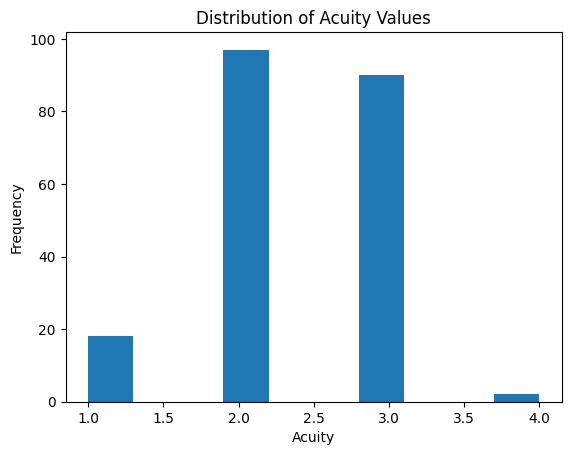

,chiefcomplaint
0,PICC EVAL
1,FACIAL DROOP
2,MVC/INTUBATED TRAUMA
3,S/P ARREST
4,HEAD BLEED


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

'''
The MIMIC-IV dataset contains 26 csv files. The MIMIC-IV-ED dataset contains 6 csv files.

The module of interest is MIMIC-IV-ED, containing 6 csv's: edstays, triage, vitalsign, diagnosis, medrecon, pyxis.

This document will explore these 6 csv's, and evaluate variables of interest.
'''

# import csv from google drive
from google.colab import drive
drive.mount('/content/drive')

# import csv from google drive
print(os.listdir('drive/MyDrive/1A AIH Group Project/MIMIC demo data'))

diagnosis = pd.read_csv('drive/MyDrive/1A AIH Group Project/MIMIC demo data/diagnosis.csv')
edstays = pd.read_csv('drive/MyDrive/1A AIH Group Project/MIMIC demo data/edstays.csv')
medrecon = pd.read_csv('drive/MyDrive/1A AIH Group Project/MIMIC demo data/medrecon.csv')
pyxis = pd.read_csv('drive/MyDrive/1A AIH Group Project/MIMIC demo data/pyxis.csv')
triage = pd.read_csv('drive/MyDrive/1A AIH Group Project/MIMIC demo data/triage.csv')
vitalsign = pd.read_csv('drive/MyDrive/1A AIH Group Project/MIMIC demo data/vitalsign.csv')


print(f'\nColumns in diagnosis table: \n{diagnosis.dtypes}')
print(f'\nColumns in edstays table: \n{edstays.dtypes}')
print(f'\nColumns in medrecon table: \n{medrecon.dtypes}')
print(f'\nColumns in pyxis table: \n{pyxis.dtypes}')
print(f'\nColumns in triage table: \n{triage.dtypes}')


# Lets investigate the outcome variable, acuity, in the triage table

print(f'\nSize of triage table: {triage.shape}')
print(f'\nValue counts in acuity column: {triage["acuity"].value_counts()}')
print(f'\nTotal missing values in acuity column: {triage["acuity"].isna().sum()}\n')

print(f'Proportion of missing values in acuity column: {round((triage["acuity"].isna().sum()/len(triage))*100,2)}%\n')

# Histogram showing distribution of acuity values
plt.hist(triage["acuity"])
plt.xlabel("Acuity")
plt.ylabel("Frequency")
plt.title("Distribution of Acuity Values")
plt.show()

triage['chiefcomplaint'].head()

In [5]:
# Print head(5) for the first 5 rows of each dataset
print(f'\nColumns in diagnosis table: \n{diagnosis.head()}')
print(f'\nColumns in edstays table: \n{edstays.head()}')
print(f'\nColumns in medrecon table: \n{medrecon.head()}')
print(f'\nColumns in pyxis table: \n{pyxis.head()}')
print(f'\nColumns in triage table: \n{triage.head()}')



Columns in diagnosis table: 
   subject_id   stay_id  seq_num icd_code  icd_version  \
0    10025463  35470228        1      431            9   
1    10027602  36678718        1      431            9   
2    10009049  31628990        1      486            9   
3    10014078  38676365        1     3453            9   
4    10007928  39661025        1     5780            9   

                        icd_title  
0        INTRACEREBRAL HEMORRHAGE  
1        INTRACEREBRAL HEMORRHAGE  
2  PNEUMONIA,ORGANISM UNSPECIFIED  
3                GRAND MAL STATUS  
4                     HEMATEMESIS  

Columns in edstays table: 
   subject_id     hadm_id   stay_id               intime              outtime  \
0    10014729  23300884.0  37887480  2125-03-19 12:36:00  2125-03-19 16:59:47   
1    10018328  26706939.0  34176810  2154-02-05 17:09:00  2154-02-05 22:54:00   
2    10018328         NaN  32103106  2154-08-03 15:31:00  2154-08-03 22:29:00   
3    10020640  27984218.0  38797992  2153-02-12 21:59